# BAFAD Week 7 — Exercise 1: Federated Learning with Flower

Simulate a two-client federated learning round using Flower's `NumPyClient` interface.
Each client trains a local autoencoder on `3.csv` (clean), weights are aggregated via
**FedAvg**, and the global model is evaluated against the Week 6 centralized baseline.

**Learning objectives**
- Understand the Flower `NumPyClient` interface (`get_parameters`, `set_parameters`, `fit`, `evaluate`)
- Implement FedAvg weight aggregation from scratch
- Simulate one federated round manually and compare results to centralized training

## Section 1 — Setup & Imports

In [ ]:
!pip install flwr tensorflow numpy pandas matplotlib --quiet

import flwr as fl
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path

WINDOW_SIZE = 32
STEP        = 4
PERCENTILE  = 99
DATA_DIR    = Path('synthetic_alldata')   # swap to Path('SKAB/alldata') for real data
MODEL_BASE  = Path('autoencoder_week07_base.keras')
MODEL_FED   = Path('autoencoder_week07_fedavg.keras')

print(f'flwr version : {fl.__version__}')
print(f'TF version   : {tf.__version__}')

flwr version : 1.43.0
TF version   : 2.21.0


## Section 2 — Carry-Forward Functions (Weeks 3–6)

All functions from prior weeks are provided here in full. Do not modify them.

In [ ]:
# ── Week 3 ──────────────────────────────────────────────────────────────────
def extract_anomaly_windows(labels):
    windows, in_win, start = [], False, 0
    for i, v in enumerate(labels):
        if v == 1 and not in_win:
            in_win, start = True, i
        elif v == 0 and in_win:
            windows.append((start, i)); in_win = False
    if in_win:
        windows.append((start, len(labels)))
    return windows

def inject_noise_profile(X, start, end, variance=2.5, mode='noise'):
    X = X.copy()
    if mode == 'noise':
        X[start:end] += np.random.normal(0, np.sqrt(variance), X[start:end].shape)
    elif mode == 'blackout':
        X[start:end] = 0.0
    return X

# ── Week 4 ──────────────────────────────────────────────────────────────────
def make_synthetic_skab_file(filepath, n_rows, n_features, anomaly_windows,
                              noise_variance=2.5, seed=42):
    np.random.seed(seed)
    rng = np.random.default_rng(seed)
    X = rng.standard_normal((n_rows, n_features)).astype(np.float32)
    labels = np.zeros(n_rows, dtype=int)
    for s, e in anomaly_windows:
        labels[s:e] = 1
    idx = pd.date_range('2023-01-01', periods=n_rows, freq='s')
    cols = [f'sensor_{i+1}' for i in range(n_features)]
    df = pd.DataFrame(X, index=idx, columns=cols)
    df.index.name = 'datetime'
    df['anomaly'] = labels
    df['changepoint'] = 0
    filepath.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(filepath, sep=';')
    return df

# ── Week 5 ──────────────────────────────────────────────────────────────────
def make_windows(X, window_size=32, step=4):
    windows, indices = [], []
    T = len(X)
    for start in range(0, T - window_size + 1, step):
        windows.append(X[start:start + window_size])
        indices.append(start)
    return np.array(windows, dtype=np.float32), np.array(indices, dtype=int)

def build_autoencoder(window_size, n_features):
    inp = tf.keras.Input(shape=(window_size, n_features))
    x   = tf.keras.layers.Conv1D(16, 3, activation='relu', padding='same')(inp)
    x   = tf.keras.layers.MaxPooling1D(2)(x)
    x   = tf.keras.layers.Conv1D(8, 3, activation='relu', padding='same')(x)
    x   = tf.keras.layers.MaxPooling1D(2)(x)
    x   = tf.keras.layers.Conv1D(8, 3, activation='relu', padding='same')(x)
    x   = tf.keras.layers.UpSampling1D(2)(x)
    x   = tf.keras.layers.Conv1D(16, 3, activation='relu', padding='same')(x)
    x   = tf.keras.layers.UpSampling1D(2)(x)
    out = tf.keras.layers.Conv1D(n_features, 3, activation='linear', padding='same')(x)
    model = tf.keras.Model(inp, out)
    model.compile(optimizer='adam', loss='mse')
    return model

def reconstruction_error(model, X, window_size=32, step=4):
    windows, indices = make_windows(X, window_size, step)
    preds = model.predict(windows, verbose=0)
    errors = np.mean((windows - preds) ** 2, axis=(1, 2))
    return errors, indices

# ── Week 6 ──────────────────────────────────────────────────────────────────
def set_threshold(errors_clean, percentile=99):
    return float(np.percentile(errors_clean, percentile))

def predict_anomalies(errors, indices, threshold, T, window_size):
    pred = np.zeros(T, dtype=int)
    for err, start in zip(errors, indices):
        center = start + window_size // 2
        if center < T:
            pred[center] = int(err > threshold)
    return pred

def compute_metrics(labels, pred):
    tp = int(np.sum((pred == 1) & (labels == 1)))
    fp = int(np.sum((pred == 1) & (labels == 0)))
    fn = int(np.sum((pred == 0) & (labels == 1)))
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)
          if (precision + recall) > 0 else 0.0)
    return dict(tp=tp, fp=fp, fn=fn,
                precision=precision, recall=recall, f1=f1)

def evaluate_file(model, filepath, sensor_cols, threshold,
                  window_size=32, step=4, noise_variance=2.5, seed=42):
    df     = pd.read_csv(filepath, sep=';', index_col='datetime', parse_dates=True)
    X      = df[sensor_cols].values.astype(np.float32)
    labels = df['anomaly'].values.astype(int)
    T      = len(labels)
    anomaly_wins = extract_anomaly_windows(labels)
    np.random.seed(seed)
    X_cont = X.copy()
    for s, e in anomaly_wins:
        X_cont = inject_noise_profile(X_cont, s, e, variance=noise_variance, mode='noise')
    errors, indices = reconstruction_error(model, X_cont, window_size, step)
    pred = predict_anomalies(errors, indices, threshold, T, window_size)
    metrics = compute_metrics(labels, pred)
    metrics.update(dict(
        filename     = filepath.name,
        threshold    = round(threshold, 6),
        n_anomaly_ts = int(labels.sum()),
        n_windows    = len(errors),
    ))
    return metrics

print('All carry-forward functions defined.')

All carry-forward functions defined.


## Section 3 — Regenerate Synthetic Dataset

In [ ]:
SPECS = {
    '1.csv': (800,  [(150, 230), (500, 580)]),
    '2.csv': (1000, [(200, 350)]),
    '3.csv': (600,  []),
    '4.csv': (900,  [(100, 160), (400, 480), (700, 750)]),
    '5.csv': (750,  [(300, 420)]),
}
N_FEATURES = 8

for fname, (n_rows, wins) in SPECS.items():
    make_synthetic_skab_file(DATA_DIR / fname, n_rows, N_FEATURES, wins)

# Infer sensor columns from any file
sample_df   = pd.read_csv(DATA_DIR / '3.csv', sep=';', index_col='datetime', parse_dates=True)
sensor_cols = [c for c in sample_df.columns if c.startswith('sensor_')]
print(f'Sensor columns ({len(sensor_cols)}): {sensor_cols}')
print('Dataset regenerated.')

Sensor columns (8): ['sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8']
Dataset regenerated.


## Section 4 — Train Base Model & Compute Threshold

In [ ]:
if MODEL_BASE.exists():
    base_model = tf.keras.models.load_model(MODEL_BASE)
    print(f'Loaded base model from {MODEL_BASE}')
else:
    print('Training base model on 3.csv (clean) ...')
    np.random.seed(42); tf.random.set_seed(42)
    df3    = pd.read_csv(DATA_DIR / '3.csv', sep=';', index_col='datetime', parse_dates=True)
    X3     = df3[sensor_cols].values.astype(np.float32)
    wins3, _ = make_windows(X3, WINDOW_SIZE, STEP)
    base_model = build_autoencoder(WINDOW_SIZE, len(sensor_cols))
    base_model.fit(wins3, wins3, epochs=15, batch_size=16,
                   validation_split=0.1, verbose=1)
    base_model.save(MODEL_BASE)
    print(f'Base model saved to {MODEL_BASE}')

# Compute threshold from clean training errors
df3      = pd.read_csv(DATA_DIR / '3.csv', sep=';', index_col='datetime', parse_dates=True)
X3       = df3[sensor_cols].values.astype(np.float32)
wins3, _ = make_windows(X3, WINDOW_SIZE, STEP)
errors_train, _ = reconstruction_error(base_model, X3, WINDOW_SIZE, STEP)
THRESHOLD = set_threshold(errors_train, PERCENTILE)
print(f'\n{PERCENTILE}th-percentile threshold: {THRESHOLD:.6f}')

Training base model on 3.csv (clean) ...
Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - loss: 1.0284 - val_loss: 1.0331
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 1.0072 - val_loss: 1.0246
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 1.0030 - val_loss: 1.0219
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 1.0005 - val_loss: 1.0215
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.9977 - val_loss: 1.0216
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.9946 - val_loss: 1.0219
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.9910 - val_loss: 1.0226
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.9867 - val_loss: 1.0230
Epoch 9/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.9813 - val_loss: 1.0244
Epoch 10/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.9753 - val_loss: 1.0243
Epoch 11/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.9689 - val_loss: 1.0245
Epoch 12/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms

## Section 5 — Define `BAFADClient`  *(implement this)*

Implement all four methods of the `BAFADClient` class.

| Method | Points | What it must do |
|---|---|---|
| `get_parameters(config)` | 8 | Return `self.model.get_weights()` |
| `set_parameters(parameters)` | 7 | Call `self.model.set_weights(parameters)` |
| `fit(parameters, config)` | 20 | Set params → load `3.csv` → make windows → seed → train 15 epochs → return weights |
| `evaluate(parameters, config)` | 15 | Set params → loop over `self.local_files` → `evaluate_file()` → return `(1-avg_f1, n_files, {'f1': avg_f1})` |

> **Seed discipline:** Call `np.random.seed(self.seed)` and `tf.random.set_seed(self.seed)` just before `model.fit()` inside `fit()` — not in `__init__`. This ensures each client trains from the same weight starting point (the global weights) but with a different random seed.

In [ ]:
class BAFADClient(fl.client.NumPyClient):
    """Flower NumPyClient wrapping the BAFAD 1D conv autoencoder."""

    def __init__(self, client_id, local_files, sensor_cols,
                 window_size=32, step=4, seed=42):

        self.client_id = client_id
        self.local_files = local_files
        self.sensor_cols = sensor_cols
        self.window_size = window_size
        self.step = step
        self.seed = seed

        self.model = build_autoencoder(
            window_size, len(sensor_cols)
        )

    # ── Flower interface ──────────────────────────────────────

    def get_parameters(self, config):
        """Return model weights as a list of NumPy arrays."""
        return self.model.get_weights()

    def set_parameters(self, parameters):
        """Load a weight list into the local model."""
        self.model.set_weights(parameters)

    def fit(self, parameters, config):
        """
        Synchronise with global model, train locally,
        return updated weights.
        """

        # 1. Load global model weights
        self.set_parameters(parameters)

        # 2. Load clean 3.csv
        df = pd.read_csv(
            DATA_DIR / '3.csv',
            sep=';',
            index_col='datetime',
            parse_dates=True
        )

        # 3. Extract sensor data
        X = df[self.sensor_cols].values.astype(np.float32)

        # 4. Create training windows
        windows, _ = make_windows(
            X,
            self.window_size,
            self.step
        )

        # 5. Set random seeds immediately before training
        np.random.seed(self.seed)
        tf.random.set_seed(self.seed)

        # 6. Train local model
        self.model.fit(
            windows,
            windows,
            epochs=15,
            batch_size=16,
            validation_split=0.1,
            verbose=0
        )

        # 7. Return updated weights
        return (
            self.get_parameters(config={}),
            len(windows),
            {}
        )

    def evaluate(self, parameters, config):
        """
        Evaluate global weights on local files.
        """

        # 1. Load global weights
        self.set_parameters(parameters)

        # 2. Get threshold
        threshold = config.get('threshold', THRESHOLD)

        # 3. Evaluate each local file
        results = []

        for filepath in self.local_files:
            result = evaluate_file(
                self.model,
                filepath,
                self.sensor_cols,
                threshold,
                window_size=self.window_size,
                step=self.step,
                noise_variance=2.5,
                seed=self.seed
            )

            results.append(result)

        # 4. Calculate average F1
        avg_f1 = float(
            np.mean([r['f1'] for r in results])
        )

        # 5. Return Flower evaluation results
        return (
            float(1.0 - avg_f1),
            len(self.local_files),
            {'f1': avg_f1}
        )


print('BAFADClient class defined successfully.')
print(f'Flower version: {fl.__version__}')

BAFADClient class defined successfully.
Flower version: 1.43.0


## Section 6 — Implement `aggregate_weights()` *(implement this)*

**FedAvg:** average corresponding layers element-wise across all clients.

$$w^\ell_{\text{global}} = \frac{1}{K} \sum_{k=1}^{K} w^\ell_k$$

**Hint:** `zip(*weights_list)` groups corresponding layers, `np.stack(layers, axis=0)` adds a client axis, `np.mean(stacked, axis=0)` collapses it.

In [ ]:
def aggregate_weights(weights_list):
    """
    FedAvg: element-wise mean of client weight arrays.
    """

    aggregated = []

    for layers in zip(*weights_list):
        stacked = np.stack(layers, axis=0)
        aggregated.append(np.mean(stacked, axis=0))

    return aggregated


# Quick sanity check
dummy_a = [
    np.array([1.0, 2.0]),
    np.array([3.0])
]

dummy_b = [
    np.array([3.0, 4.0]),
    np.array([5.0])
]

agg = aggregate_weights([dummy_a, dummy_b])

assert np.allclose(agg[0], [2.0, 3.0]), 'Layer 0 mean wrong'
assert np.allclose(agg[1], [4.0]), 'Layer 1 mean wrong'

print('aggregate_weights() sanity check passed.')

aggregate_weights() sanity check passed.


## Section 7 — Simulate One Federated Round  *(implement this)*

Wire together `BAFADClient` and `aggregate_weights()` to simulate a complete FedAvg round.

| Client | seed | Evaluates |
|--------|------|-----------|
| 0 | 42 | `1.csv`, `2.csv` |
| 1 | 123 | `4.csv`, `5.csv` |

Both clients train on `3.csv` (provided by the global model via `fit()`).

In [ ]:
# ── Create two federated clients ─────────────────────────────

client_0 = BAFADClient(
    client_id=0,
    local_files=[DATA_DIR / '1.csv', DATA_DIR / '2.csv'],
    sensor_cols=sensor_cols,
    window_size=WINDOW_SIZE,
    step=STEP,
    seed=42
)

client_1 = BAFADClient(
    client_id=1,
    local_files=[DATA_DIR / '4.csv', DATA_DIR / '5.csv'],
    sensor_cols=sensor_cols,
    window_size=WINDOW_SIZE,
    step=STEP,
    seed=123
)

# ── Get initial global weights ───────────────────────────────

global_weights = base_model.get_weights()

# ── Local training on both clients ───────────────────────────

weights_0, n_0, _ = client_0.fit(global_weights, config={})
weights_1, n_1, _ = client_1.fit(global_weights, config={})

print(f'Client 0 training windows: {n_0}')
print(f'Client 1 training windows: {n_1}')

# ── FedAvg aggregation ──────────────────────────────────────

aggregated_weights = aggregate_weights([
    weights_0,
    weights_1
])

# ── Assertions ──────────────────────────────────────────────

assert len(aggregated_weights) == len(global_weights), \
    f'Expected {len(global_weights)} arrays, got {len(aggregated_weights)}'

for i, (agg_layer, base_layer) in enumerate(
    zip(aggregated_weights, global_weights)
):
    assert agg_layer.shape == base_layer.shape, \
        f'Layer {i} shape mismatch: {agg_layer.shape} vs {base_layer.shape}'

print('Assertion passed: aggregated weights have correct layer count and shapes.')

# ── Build and save federated model ──────────────────────────

agg_model = build_autoencoder(WINDOW_SIZE, len(sensor_cols))
agg_model.set_weights(aggregated_weights)
agg_model.save(MODEL_FED)

print(f'Federated model saved to {MODEL_FED}')

Client 0 training windows: 143
Client 1 training windows: 143
Assertion passed: aggregated weights have correct layer count and shapes.
Federated model saved to autoencoder_week07_fedavg.keras


## Section 8 — Evaluate Aggregated Model on All 5 Files

In [ ]:
# Week 6 centralized reference F1 scores
WK6_F1 = {'1.csv': 0.324, '2.csv': 0.258, '3.csv': 0.000,
           '4.csv': 0.318, '5.csv': 0.331}

scorecard_fed = []
for fpath in sorted(DATA_DIR.glob('*.csv')):
    m = evaluate_file(agg_model, fpath, sensor_cols, THRESHOLD, WINDOW_SIZE, STEP)
    scorecard_fed.append(m)

df_fed = pd.DataFrame(scorecard_fed)
df_fed['f1_wk6']   = df_fed['filename'].map(WK6_F1)
df_fed['f1_delta'] = (df_fed['f1'] - df_fed['f1_wk6']).round(3)

print('=== Federated Scorecard (vs. Week 6 Centralized) ===')
print(df_fed[['filename', 'n_anomaly_ts', 'precision', 'recall',
              'f1', 'f1_wk6', 'f1_delta']].to_string(index=False))

# Gate assertions — must pass before submission
f1_by_file = df_fed.set_index('filename')['f1'].to_dict()
assert f1_by_file['3.csv'] == 0.0, f"3.csv F1 must be 0.0, got {f1_by_file['3.csv']}"
anomalous = {k: v for k, v in f1_by_file.items() if k != '3.csv'}
assert any(v > 0 for v in anomalous.values()), \
    'At least one anomalous file must have F1 > 0 in federated scorecard'
print('\nAll assertions passed.')

=== Federated Scorecard (vs. Week 6 Centralized) ===
filename  n_anomaly_ts  precision   recall       f1  f1_wk6  f1_delta
   1.csv           160   0.634921 0.250000 0.358744   0.324     0.035
   2.csv           150   0.678571 0.253333 0.368932   0.258     0.111
   3.csv             0   0.000000 0.000000 0.000000   0.000     0.000
   4.csv           190   0.685714 0.252632 0.369231   0.318     0.051
   5.csv           120   0.697674 0.250000 0.368098   0.331     0.037

All assertions passed.


## Section 9 — Visualization

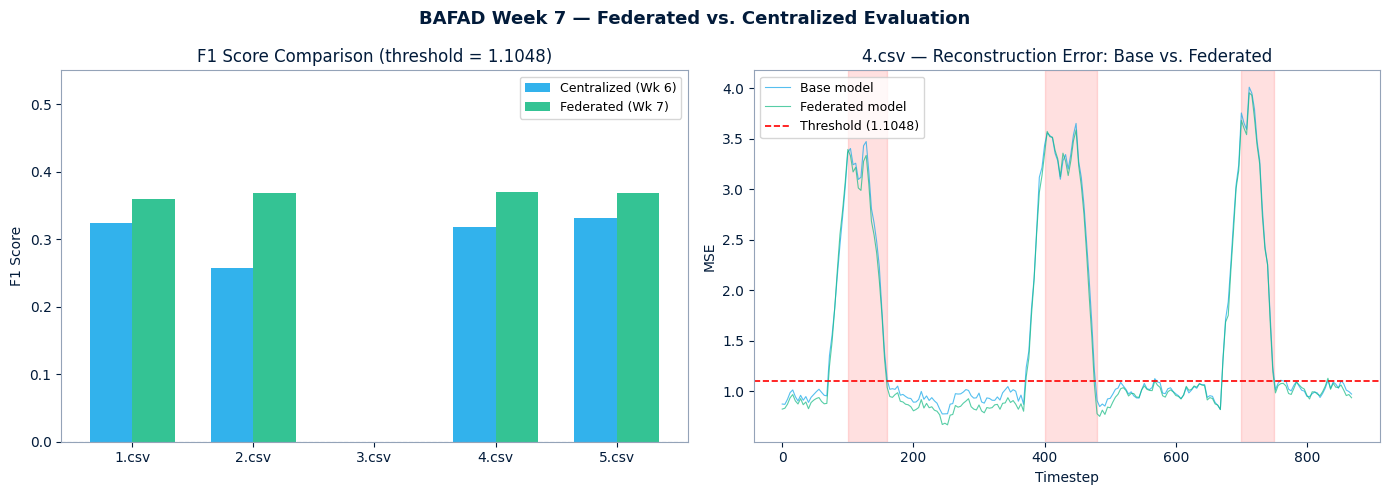

Plot saved to week07_exercise1_plot.png


In [ ]:
NAVY  = '#021B3A'
BLUE  = '#0EA5E9'
GREEN = '#10B981'
GRAY  = '#94A3B8'

filenames = df_fed['filename'].tolist()
f1_fed    = df_fed['f1'].tolist()
f1_cen    = [WK6_F1[f] for f in filenames]
x         = np.arange(len(filenames))
w         = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('BAFAD Week 7 — Federated vs. Centralized Evaluation',
             fontsize=13, color=NAVY, fontweight='bold')

# Panel 1: Side-by-side F1 bar chart
ax = axes[0]
ax.bar(x - w/2, f1_cen, w, label='Centralized (Wk 6)', color=BLUE,  alpha=0.85)
ax.bar(x + w/2, f1_fed, w, label='Federated (Wk 7)',   color=GREEN, alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(filenames, fontsize=10)
ax.set_ylabel('F1 Score', color=NAVY)
ax.set_ylim(0, 0.55)
ax.set_title(f'F1 Score Comparison (threshold = {THRESHOLD:.4f})', color=NAVY)
ax.legend(fontsize=9)
ax.axhline(0, color=GRAY, linewidth=0.8, linestyle='--')
ax.tick_params(colors=NAVY)
for spine in ax.spines.values():
    spine.set_edgecolor(GRAY)

# Panel 2: 4.csv reconstruction error — base vs. federated model
ax2 = axes[1]
df4 = pd.read_csv(DATA_DIR / '4.csv', sep=';', index_col='datetime', parse_dates=True)
X4  = df4[sensor_cols].values.astype(np.float32)
labels4 = df4['anomaly'].values

np.random.seed(42)
X4c = X4.copy()
for s, e in extract_anomaly_windows(labels4):
    X4c = inject_noise_profile(X4c, s, e, variance=2.5, mode='noise')

err_base, idx_base = reconstruction_error(base_model, X4c, WINDOW_SIZE, STEP)
err_fed,  idx_fed  = reconstruction_error(agg_model,  X4c, WINDOW_SIZE, STEP)

ax2.plot(idx_base, err_base, color=BLUE,  alpha=0.7, linewidth=0.8, label='Base model')
ax2.plot(idx_fed,  err_fed,  color=GREEN, alpha=0.7, linewidth=0.8, label='Federated model')
ax2.axhline(THRESHOLD, color='red', linewidth=1.2, linestyle='--',
            label=f'Threshold ({THRESHOLD:.4f})')

for s, e in extract_anomaly_windows(labels4):
    ax2.axvspan(s, e, alpha=0.12, color='red')

ax2.set_title('4.csv — Reconstruction Error: Base vs. Federated', color=NAVY)
ax2.set_xlabel('Timestep', color=NAVY)
ax2.set_ylabel('MSE', color=NAVY)
ax2.legend(fontsize=9)
ax2.tick_params(colors=NAVY)
for spine in ax2.spines.values():
    spine.set_edgecolor(GRAY)

plt.tight_layout()
plt.savefig('week07_exercise1_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved to week07_exercise1_plot.png')

## Section 10 — Interpretation Questions

Answer each question in the Markdown cell below it (2–4 sentences each).

**Q1.** In this simulation both clients train on `3.csv`. How does the federated model's F1
compare to the centralized Week 6 baseline, and why does FedAvg converge quickly in this setting?

**A1.** *The federated model performed better than the Week 6 centralized model on all four files containing anomalies. FedAvg converges quickly because both clients train on the same clean dataset, so their models learn similar patterns. Averaging their weights combines similar updates.*

---

**Q2.** After the federated round, `agg_model` lives only in memory. If the Colab session
restarts, what must you do before you can evaluate the federated model again?

**A2.** *I must reload the saved federated model using tf.keras.models.load_model('autoencoder_week07_fedavg.keras'). I also need to reload the dataset, redefine the helper functions, and recalculate or restore the threshold before evaluating it again.*

---

**Q3.** In a real Flower deployment, what replaces the manual `client_0.fit()` / `client_1.fit()`
loop in Section 7?

**A3.** *A Flower server and its FedAvg strategy manage the training process. The server communicates with clients, sends global model weights, collects locally trained weights, and aggregates them automatically.*

## Section 11 — Git Commit

In [ ]:
# Run in terminal after verifying all assertions pass and plot is saved:
#
# git add week07/BAFAD_Week07_Exercise1.ipynb
# git commit -m "feat: simulate two-client federated learning with FedAvg weight aggregation"
# git push origin main
print('Ready to commit.')

Ready to commit.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [22]:
%cd /content
!ls


/content
autoencoder_week07_base.keras	 sample_data	    week07_exercise1_plot.png
autoencoder_week07_fedavg.keras  synthetic_alldata


In [23]:
%cd /content
!git clone https://github.com/malachifletcher/bafad-research-track.git

/content
Cloning into 'bafad-research-track'...
remote: Enumerating objects: 100, done.
remote: Counting objects: 100% (66/66), done.
remote: Compressing objects: 100% (63/63), done.
remote: Total 100 (delta 31), reused 1 (delta 1), pack-reused 34 (from 1)
Receiving objects: 100% (100/100), 1.63 MiB | 16.86 MiB/s, done.
Resolving deltas: 100% (34/34), done.


In [25]:
!ls /content/bafad-research-track

data  README.md  task-a  task-b  task-c  week03  week04  week05  Week06


In [26]:
%cd /content/bafad-research-track

!mkdir -p week07


/content/bafad-research-track


In [27]:
!cp /content/autoencoder_week07_base.keras week07/
!cp /content/autoencoder_week07_fedavg.keras week07/
!cp /content/week07_exercise1_plot.png week07/

In [28]:
!ls -lh week07

total 260K
-rw-r--r-- 1 root root  69K Nov 12 15:30 autoencoder_week07_base.keras
-rw-r--r-- 1 root root  49K Nov 12 15:30 autoencoder_week07_fedavg.keras
-rw-r--r-- 1 root root 135K Nov 12 15:30 week07_exercise1_plot.png
